# COMP7015 Group Project – Topic 1: Plant Disease Classification

This notebook classifies tomato leaf images from the [PlantVillage dataset](https://github.com/spMohanty/PlantVillage-Dataset) into **healthy, bacterial spot, early blight and late blight**. The main question is how much the models rely on the photo background and whether training with random backgrounds helps. It follows a report of class-specific bias in PlantVillage: a classifier that sees only eight pixels from the border of a photo already predicts the class far above chance (Noyan, 2022). It uses a strict data protocol, compares a custom CNN with attention, a fine-tuned ResNet18 and a fine-tuned Vision Transformer, and evaluates them beyond the clean test set: a check how much the background alone tells (5.1), uncertainty estimates for all scores (Sections 10.1, 10.2 and 13.1), a test that changes only the background of the same leaf (13.2), a measure of where the models look (13.3), a countermeasure for the background shortcut (Section 14) and tests on photo series that were left out of training and on field photos (Section 15):

| Rubric criterion (Excellent) | What the notebook does | Section |
|---|---|---|
| Reproducible leaf-group splits, no leakage | One training series per class with official leaf ids only (other series are test-only), images without leaf information excluded, near-duplicate merging and cross-split audit | 3, 4, 5 |
| Efficient caching / IO | Images are decoded and resized **once** and cached as a uint8 tensor | 4 |
| Justified class balance | Class-weighted loss, tested in an ablation | 6, 9 |
| Sound fine-tuning (freeze/unfreeze, schedulers) | Two-stage fine-tuning (train head → unfreeze backbone), AdamW, cosine LR schedule, gradient clipping, checkpoints | 7, 8 |
| Attention / transformer modelling | Custom CNN with **Squeeze-and-Excitation channel attention** and a pre-trained **Vision Transformer (ViT-B/16)** | 7 |
| Systematic tuning and ablations | Learning-rate sweep, ablations of attention, augmentation, dropout, class weighting, scheduler and batch size, plus a comparison of fine-tuning strategies | 9 |
| Per-class metrics, macro-F1, confusion matrix, error analysis | Mean ± std over 3 seeds, per-class F1, confusion matrices, misclassified images, Grad-CAM | 10, 12 |
| Compute trade-offs | Parameters, model size, training time, inference latency | 11 |
| Background bias / robustness | Test leaves with background removed, grayscale, darker, blurred and noisy; the same leaf on a background of its own class and of another class; share of the Grad-CAM weight that lies on the leaf | 13 |
| Reliable model comparison | Bootstrap confidence intervals over leaf groups, paired comparison of the models on the same test leaves, seed spread under distribution shift, risk-coverage curves and calibration error | 10, 13, 16 |
| Countermeasure for the background shortcut | Training with random backgrounds, the same-leaf background tests, evaluation on a background type that never occurs in training, an explicit tolerance for the cost on clean photos | 14 |
| Unseen photo series and field photos | Series that were left out of training and PlantDoc field photos are used as tests of all trained models, without retraining | 15 |
| Deterministic, config-driven | One `CFG` dictionary, saved with every run; fixed seeds; deterministic algorithms | 1 |

**Runtime.** Every training run is saved under `OUT_DIR/runs/`. Re-running the notebook loads finished runs instead of retraining them, so an interrupted run can simply be resumed. The notebook trains many models (tuning, final models, countermeasure and control), so the runtime depends strongly on the hardware and a GPU is recommended. Section 11 reports the time per model. The ViT is the slowest model.

**Notebooks.** The project is split into five notebooks that run in order: `01_data` (Sections 1–6), `02_models_and_tuning` (7–9), `03_test_evaluation` (10–12), `04_background_bias` (13–14) and `05_generalisation` (15–17). The shared code (data protocol, models, training engine, evaluation tools) lives in the `plantdisease/` package; the notebooks show the steps and the results.

## 1. Setup & Configuration

All settings live in one `CFG` dictionary (`plantdisease/config.py`). Paths, epochs and seeds can also be overridden with environment variables without editing the notebook, e.g. `EPOCHS_CNN=1 SEEDS=42` for a quick test. The configuration is saved to `OUT_DIR/config.json`. The notebooks need Python 3.10 or newer, PyTorch 2.0 or newer and torchvision 0.15 or newer (`transforms.v2`).

In [2]:
import os
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from PIL import Image
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
from torchvision.utils import make_grid

from plantdisease.config import CFG, CLASSES, SHORT_NAMES, USE_AMP, device, out_path
from plantdisease.data import (
    DATA_ROOT,
    CachedDataset,
    border_brightness,
    build_cache,
    chunked,
    class_weights,
    data_fingerprint,
    dhash_bits,
    download_plantvillage,
    load_records,
    make_loader,
    make_split,
    merge_near_duplicates,
    train_tf,
)
from plantdisease.plots import finish

In [3]:
CFG  # saved to OUT_DIR/config.json

{'data_root': './PlantVillage-Dataset',
 'cache_dir': './cache',
 'out_dir': './outputs',
 'classes': ['Tomato___healthy',
  'Tomato___Bacterial_spot',
  'Tomato___Early_blight',
  'Tomato___Late_blight'],
 'train_series': {'Tomato___healthy': 'rs_hl',
  'Tomato___Bacterial_spot': 'gcrec_bact.sp',
  'Tomato___Early_blight': 'rs_erly.b',
  'Tomato___Late_blight': 'rs_late.b'},
 'field_root': './PlantDoc-Dataset',
 'field_photos': {'url': 'https://github.com/pratikkayal/PlantDoc-Dataset',
  'folders': {'Tomato___healthy': 'Tomato leaf',
   'Tomato___Bacterial_spot': 'Tomato leaf bacterial spot',
   'Tomato___Early_blight': 'Tomato Early blight leaf',
   'Tomato___Late_blight': 'Tomato leaf late blight'}},
 'min_series_photos': 20,
 'img_size': 224,
 'split_seed': 42,
 'split_fractions': (0.7, 0.15),
 'dup_merge_bits': 10,
 'dup_audit_bits': 20,
 'seeds': [42, 43, 44],
 'n_bootstrap': 1000,
 'epochs': {'cnn': 50, 'resnet18': 16, 'vit_b_16': 12},
 'vit_trainable_blocks': 4,
 'countermeasur

In [4]:
print("Device in use:", device, "| mixed precision:", USE_AMP)
print("torch", torch.__version__, "| torchvision", torchvision.__version__)

Device in use: mps | mixed precision: False
torch 2.15.0 | torchvision 0.29.2


## 2. Download the Data

We use a sparse git checkout with only the four tomato folders of `raw/color` (the RGB images used for training) and the root files (incl. `leaf-map.json`). We also fetch `raw/segmented`, the same photos with the background removed. They are used in Sections 13 and 14 to test background bias and to cut the leaf out of the photo.

In [5]:
folders = download_plantvillage()  # sparse git checkout, skipped if the folders exist
for f in folders:
    print(f"{f:40s} {len(os.listdir(os.path.join(DATA_ROOT, f)))} images")

Cloning into './PlantVillage-Dataset'...
remote: Enumerating objects: 206, done.
remote: Counting objects: 100% (206/206), done.
remote: Compressing objects: 100% (169/169), done.
remote: Total 206 (delta 37), reused 204 (delta 37), pack-reused 0 (from 0)
Receiving objects: 100% (206/206), 7.47 MiB | 862.00 KiB/s, done.
Resolving deltas: 100% (37/37), done.
remote: Enumerating objects: 9, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (9/9), done.
remote: Total 9 (delta 0), reused 7 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (9/9), 255.05 KiB | 152.00 KiB/s, done.
Updating files: 100% (9/9), done.
remote: Enumerating objects: 13226, done.
remote: Counting objects: 100% (13226/13226), done.
remote: Compressing objects: 100% (13226/13226), done.
remote: Total 13226 (delta 0), reused 13226 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (13226/13226), 149.06 MiB | 507.00 KiB/s, done.
Updating files: 100% (13254/13254), done.
ra

## 3. Leaf Grouping & Label Verification

Every image must be assigned to a **physical leaf**, so that all photos of one leaf end up in the same split.

1. **Official metadata.** The image identifier from the file name is looked up in `leaf-map.json`, keeping only an entry of the image's own class.
2. **One training series per class.** Every class consists of several photo series (the series is the first part of the file name, for example `RS_HL` or `GHLB_PS`) with their own background, light and camera. Series without official leaf ids cannot be grouped safely, because file numbers do not identify a leaf reliably: in the greenhouse series the same leaf is photographed on several days (`GHLB Leaf 14 Day 7`, `Day 9`). We therefore train on **one series per class that has official leaf ids** (`CFG["train_series"]`). All other series are left out of training, validation and the clean test.
3. **Series test.** The left-out series are evaluated in Section 15 (leaves of the same classes from a different series). Their groups come from the file name where possible and are only used for the bootstrap intervals.
4. **Exclusion.** Photos of a training series without any leaf information are excluded.


In [5]:
# leaf ids from leaf-map.json, training series vs. left-out series (plantdisease/data.py: load_records)
leaf_map, all_df, df, other_df = load_records()

all_df.groupby(["class_name", "series"]).agg(
    photos=("path", "size"),
    official_ids=("source", lambda s: int((s == "leaf map").sum())),
    role=("training_series", lambda s: "training" if s.all() else "series test only"),
).loc[CLASSES]

photos  official_ids  \
class_name              series                                          
Tomato___healthy        2700323949_95aa2eaa01_o       1             0   
                        cg1                           1             0   
                        gh_hl                       590             0   
                        rs_hl                       999           999   
Tomato___Bacterial_spot gcrec_bact.sp              1756          1756   
                        uf.grc_bs_lab               371           371   
Tomato___Early_blight   rs_erly.b                  1000           999   
Tomato___Late_blight    gh_hl                         2             0   
                        ghlb                         66             0   
                        ghlb2                       744             0   
                        ghlb2es                      27             0   
                        ghlb_ps                     150             0   
                        rs_late.b                   920           920   

                                                             role  
class_name              series                                     
Tomato___healthy        2700323949_95aa2eaa01_o  series test only  
                        cg1                      series test only  
                        gh_hl                    series test only  
                        rs_hl                            training  
Tomato___Bacterial_spot gcrec_bact.sp                    training  
                        uf.grc_bs_lab            series test only  
Tomato___Early_blight   rs_erly.b                        training  
Tomato___Late_blight    gh_hl                    series test only  
                        ghlb                     series test only  
                        ghlb2                    series test only  
                        ghlb2es                  series test only  
                        ghlb_ps                  series test only  
                        rs_late.b                        training

In [6]:
# Label check (all photos, before any filtering): the class stored in the leaf map must agree with the folder label
map_classes = all_df["key"].map(
    lambda k: {e.split(":::")[0] for e in leaf_map.get(k, [])}
)
conflicts = sum(
    len(m) > 0 and c not in m
    for c, m in zip(all_df["class_name"], map_classes, strict=True)
)
print("Images whose leaf-map class disagrees with the folder label:", conflicts)

# Image check: every file must open; record (size, mode)
image_info = Counter()
for p in df["path"]:
    with Image.open(p) as img:
        image_info[(img.size, img.mode)] += 1
print("Image (size, mode) counts:", dict(image_info))

Images whose leaf-map class disagrees with the folder label: 0
Image (size, mode) counts: {((256, 256), 'RGB'): 4674}


## 4. Image Cache, Near-Duplicates & Background Analysis

**Caching.** Decoding JPEGs and resizing them in every epoch is wasted work. Each image is decoded, converted to RGB and resized to 224×224 **once**, then stored as one `uint8` tensor (≈1 GB) in `cache/`. Training then only applies cheap tensor operations. The cache is rebuilt automatically if the image list or size changes.

**Near-duplicates.** The metadata cannot catch every repeated photo of a leaf. We compute a 256-bit *difference hash* (dHash) of every image. It compares neighbouring pixels of a 17×16 grayscale thumbnail and changes little under re-encoding or small shifts. Images of the same class whose hashes differ in ≤ 10 bits are merged into one group (union–find) **before** splitting. We checked looser thresholds by eye: they mostly match *different* leaves photographed on the same plain background.

**Background.** We also measure the brightness of a 12-pixel border around every image, to see whether the photo background differs between classes. Every class comes from its own photo series, so it does, and a model could learn the background instead of the disease.

In [7]:
t0 = time.time()
# decoded + resized once, uint8 (N, 3, 224, 224)
IMAGES = build_cache(df["path"], "color")
LABELS = torch.tensor(df["label"].values)
print(
    f"Cached images: {tuple(IMAGES.shape)}, {IMAGES.numel() / 1e9:.2f} GB, {time.time() - t0:.1f}s"
)

Cached images: (4674, 3, 224, 224), 0.70 GB, 4.2s


In [8]:
HASHES = chunked(dhash_bits, IMAGES)  # 256-bit difference hash of every image
# union-find within each class -> df["group"]
merges = merge_near_duplicates(df, HASHES)
print(
    f"Near-duplicate merges: {merges} | leaf ids: {df.leaf_id.nunique()} -> groups: {df.group.nunique()}"
)

Near-duplicate merges: 0 | leaf ids: 1169 -> groups: 1169


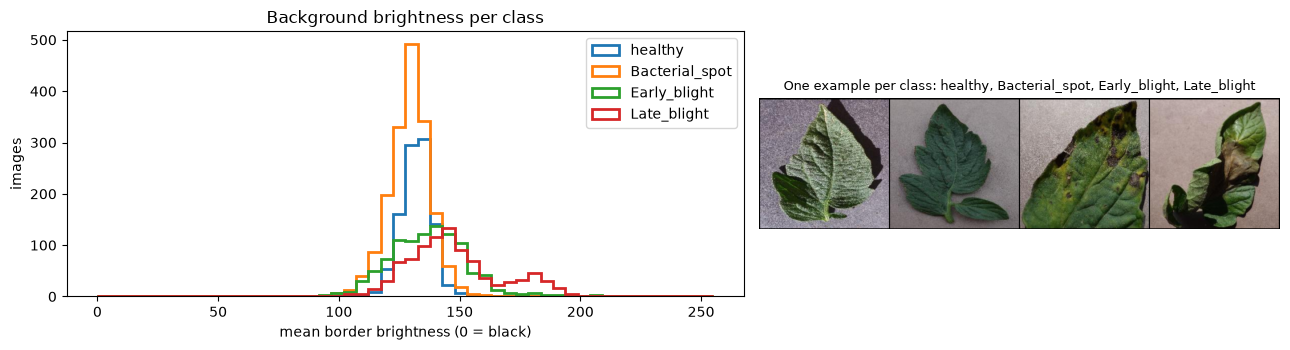

,mean,std,min,max
class_name,,,,
Tomato___healthy,132.0,6.0,108.0,152.0
Tomato___Bacterial_spot,129.0,9.0,89.0,161.0
Tomato___Early_blight,137.0,16.0,92.0,216.0
Tomato___Late_blight,148.0,19.0,83.0,215.0


In [9]:
# Background brightness: mean gray level of a 12-pixel border around each image
df["border_brightness"] = chunked(border_brightness, IMAGES).numpy()

fig, axes = plt.subplots(
    1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1.3, 1]}
)
for c, name in enumerate(SHORT_NAMES):
    axes[0].hist(
        df.loc[df.label == c, "border_brightness"],
        bins=50,
        range=(0, 255),
        histtype="step",
        linewidth=2,
        label=name,
    )
axes[0].set_xlabel("mean border brightness (0 = black)")
axes[0].set_ylabel("images")
axes[0].set_title("Background brightness per class")
axes[0].legend()
examples = [df.index[df.label == c][0] for c in range(len(CLASSES))]
grid = make_grid(IMAGES[examples], nrow=len(CLASSES), padding=2)
axes[1].imshow(grid.permute(1, 2, 0))
axes[1].set_title("One example per class: " + ", ".join(SHORT_NAMES), fontsize=9)
axes[1].axis("off")
finish("background_brightness.png")

df.groupby("class_name")["border_brightness"].agg(
    ["mean", "std", "min", "max"]
).reindex(CLASSES).round(0)

## 5. Leaf-Group Split & Leakage Audit

Within each class, the merged leaf groups are shuffled with a fixed seed and split 70 / 15 / 15 into train / validation / test. The split seed is separate from the training seeds, so all models and seeds share **exactly the same split**. We then audit the split:
1. no leaf group (and therefore no official leaf id) appears in two splits;
2. no pair of near-duplicate images (≤ 20 differing bits, twice the merge threshold) crosses splits.

In [10]:
# 70/15/15 split of the leaf groups of every class; both audits are asserted inside make_split
train_idx, val_idx, test_idx, cross = make_split(df, HASHES)
print(
    f"Split seed: {CFG['split_seed']} | near-duplicate pairs (<= {CFG['dup_audit_bits']} bits) across splits: {cross}"
)
# fingerprint of the training photos, the series and the split seed: a saved run is only reused for the same data
DATA_ID = data_fingerprint(df, train_idx)

df[["path", "class_name", "leaf_id", "group", "split"]].to_csv(
    out_path("split.csv"), index=False
)
counts = pd.crosstab(df["class_name"], df["split"], margins=True).reindex(
    [*CLASSES, "All"]
)[["train", "val", "test", "All"]]
counts["groups"] = [
    *df.groupby("class_name")["group"].nunique().reindex(CLASSES).tolist(),
    df.group.nunique(),
]
counts.to_csv(out_path("class_counts.csv"))
counts

Split seed: 42 | near-duplicate pairs (<= 20 bits) across splits: 0


split,train,val,test,All,groups
class_name,,,,,
Tomato___healthy,699,152,148,999,250
Tomato___Bacterial_spot,1228,264,264,1756,439
Tomato___Early_blight,699,152,148,999,250
Tomato___Late_blight,644,136,140,920,230
All,3270,704,700,4674,1169


### 5.1 How much does the background alone tell?

Noyan (2022) reported that a classifier that sees only eight pixels from the border of a PlantVillage photo predicts the class far above chance (49% on 38 classes). Every class here comes from its own photo series, so the background may already reveal the class. A random forest sees **only the mean colour of the four image corners** (12 numbers per photo, no leaf) and is trained on the training photos and evaluated on the validation photos (the test photos stay untouched). Two reference points tell what the score means: guessing uniformly (25%) and always answering with the largest class. A score far above both means that the background alone predicts the class. This follows the idea of Noyan (2022) for our four classes; it is not a replication.


In [11]:
def corner_features(images, size=24):
    # Mean colour of the four image corners: the background only, 12 numbers per photo.
    corners = [
        images[:, :, :size, :size],
        images[:, :, :size, -size:],
        images[:, :, -size:, :size],
        images[:, :, -size:, -size:],
    ]
    return torch.cat([c.float().mean(dim=(2, 3)) for c in corners], dim=1).numpy()


X_corners, y_all = corner_features(IMAGES), LABELS.numpy()
corner_model = RandomForestClassifier(
    n_estimators=200, random_state=CFG["split_seed"], n_jobs=-1
).fit(X_corners[train_idx], y_all[train_idx])
corner_pred = corner_model.predict(X_corners[val_idx])
majority_pred = np.full(len(val_idx), np.bincount(y_all[train_idx]).argmax())
background_only = pd.DataFrame(
    {
        "accuracy": [
            accuracy_score(y_all[val_idx], corner_pred),
            accuracy_score(y_all[val_idx], majority_pred),
        ],
        "macro-F1": [
            f1_score(y_all[val_idx], corner_pred, average="macro"),
            f1_score(y_all[val_idx], majority_pred, average="macro"),
        ],
    },
    index=["four image corners only", "always the largest class (reference)"],
)
background_only.to_csv(out_path("background_only.csv"))
background_only.round(3)

,accuracy,macro-F1
four image corners only,0.831,0.815
always the largest class (reference),0.375,0.136


## 6. Preprocessing, Augmentation & Class Weights

The cached images are already resized to 224×224. Every split is converted to float in [0, 1] and normalised with the ImageNet mean/std.

**Training-only augmentation** must not change the symptoms:
- horizontal/vertical flips and **rotations by multiples of 90°**, because a leaf has no fixed orientation. These rotations are lossless and add no black corners. Black corners matter here, because the background brightness differs between classes (Section 4).
- a mild brightness/contrast jitter (±10%) for lighting changes. There is no hue/saturation change, so lesion colours (yellow halos, brown spots) are preserved.

**Class balance.** Bacterial spot has about 2× more training images than early blight. Rather than throwing data away, we use a **class-weighted cross-entropy loss** with weight $w_c = N / (K \cdot n_c)$. Errors on rare classes then cost more. Section 9 tests whether this helps.

The transforms, the cached dataset and the loaders are defined in `plantdisease/data.py`.

Class weights: {'healthy': np.float32(1.17), 'Bacterial_spot': np.float32(0.666), 'Early_blight': np.float32(1.17), 'Late_blight': np.float32(1.269)}


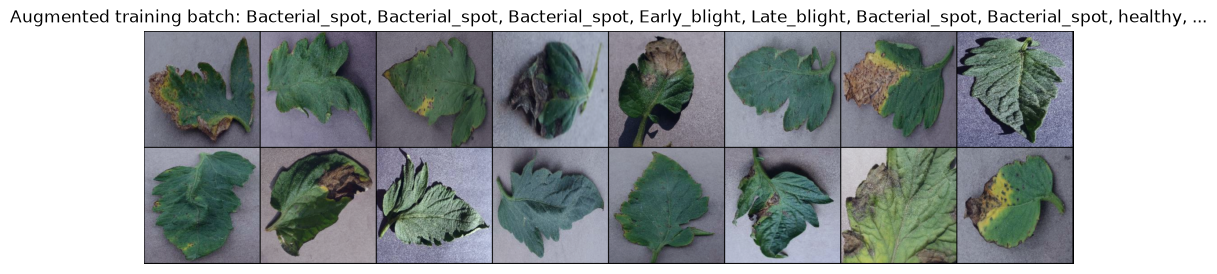

In [12]:
CLASS_WEIGHTS = class_weights(df, train_idx)  # w_c = N / (K * n_c)
print(
    "Class weights:",
    dict(zip(SHORT_NAMES, CLASS_WEIGHTS.numpy().round(3), strict=True)),
)

# Visualise augmented training images
x, y = next(
    iter(make_loader(CachedDataset(IMAGES, LABELS, train_idx, train_tf), 16, seed=0))
)
plt.figure(figsize=(12, 3.5))
plt.imshow(make_grid(x, nrow=8, padding=2, normalize=True).permute(1, 2, 0))
plt.axis("off")
plt.title(
    "Augmented training batch: " + ", ".join(SHORT_NAMES[c] for c in y[:8]) + ", ..."
)
plt.show()

**Hand-over.** The following notebooks rebuild exactly this data protocol with `plantdisease.data.prepare()`, which runs the same steps (records, cache, near-duplicate merging, split) from the image cache in a few seconds. The split is saved to `OUT_DIR/split.csv`.